# Proof Validity Classification

**Baseline model** · TF-IDF and logistic regression

## 1. Local environment

In VS Code, select **Python (DSA495 Proof Verification)** as the kernel. The code below checks the kernel's package versions and runs a small CUDA calculation on the local GPU. The scikit-learn baseline uses the CPU. CUDA is available for a later PyTorch model.

[Course demo · Text Classification with Encoder Models](https://github.com/SerenaYKim/DSA495-TextAnalysis/blob/master/Module03/DSA495-M03-Text-Classification-Encoder-Models.ipynb)

In [1]:
import sys

import pandas as pd
import sklearn
import torch

print(f"Python {sys.version.split()[0]}: {sys.executable}")
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"PyTorch {torch.__version__} | CUDA build: {torch.version.cuda}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Check that VS Code is using the project kernel.")

# Put a small tensor on the first local GPU and calculate there.
device = torch.device("cuda:0")
numbers = torch.arange(4, dtype=torch.float32, device=device)
sum_of_squares = numbers.square().sum().item()
print(f"GPU: {torch.cuda.get_device_name(device)}")
print(f"CUDA test: 0² + 1² + 2² + 3² = {sum_of_squares:g}")

Python 3.14.6: C:\Users\zhu25\AppData\Local\DSA495ProofVerification\.venv\Scripts\python.exe
pandas 3.1.1 | scikit-learn 1.9.1
PyTorch 2.11.0+cu128 | CUDA build: 12.8
GPU: NVIDIA RTX 2000 Ada Generation
CUDA test: 0² + 1² + 2² + 3² = 14


## 2. Load the review splits

In [2]:
from pathlib import Path

split_dir = Path("../Data/splits")

datasets = {}
label_counts = {}
for split_name in ("train", "validation", "test"):
    files = sorted((split_dir / split_name).glob("proofwiki_review_*.json"))
    rows = pd.concat([pd.read_json(file) for file in files], ignore_index=True)

    label_counts[split_name] = rows["validity"].fillna("Unclassified").value_counts()
    datasets[split_name] = rows.dropna(subset=["validity"]).reset_index(drop=True)

summary = pd.DataFrame(label_counts).T[["Valid", "Invalid", "Unclassified"]]
summary["Usable"] = summary["Valid"] + summary["Invalid"]
display(summary)

validity,Valid,Invalid,Unclassified,Usable
train,474,235,11,709
validation,74,15,1,89
test,75,14,1,89


## 3. Train the baseline

Use `theorem_text` and `proof_text` to predict `validity`. Try two TF-IDF character ranges (`ngram_range`) and three logistic regression `C` values. Smaller `C` limits how large the learned weights can grow.

Each line shows one model's validation Macro F1. Keep the highest score. If scores tie, keep the first combination tried.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline


def model_input(data):
    return data["theorem_text"] + "\n" + data["proof_text"]


def train_baseline(train_text, validation_text):
    best_score = -1
    for ngram_range in [(2, 4), (3, 5)]:
        for C in [1.0, 0.1, 10.0]:
            model = make_pipeline(
                TfidfVectorizer(analyzer="char", ngram_range=ngram_range, lowercase=False, min_df=2),
                LogisticRegression(C=C, class_weight="balanced", max_iter=1000),
            )
            model.fit(train_text, train["validity"])
            predicted = model.predict(validation_text)
            score = f1_score(validation["validity"], predicted, average="macro")
            print(f"ngram_range={ngram_range}, C={C:g} | Validation Macro F1 = {score:.4f}")

            if score > best_score:
                best_score = score
                best_model = model
                best_range = ngram_range
                best_C = C

    print(f"\nBest: ngram_range={best_range}, C={best_C:g} | Validation Macro F1 = {best_score:.4f}")
    return best_model


train = datasets["train"]
validation = datasets["validation"]
baseline = train_baseline(model_input(train), model_input(validation))

ngram_range=(2, 4), C=1 | Validation Macro F1 = 0.4712
ngram_range=(2, 4), C=0.1 | Validation Macro F1 = 0.4771
ngram_range=(2, 4), C=10 | Validation Macro F1 = 0.4777
ngram_range=(3, 5), C=1 | Validation Macro F1 = 0.4712
ngram_range=(3, 5), C=0.1 | Validation Macro F1 = 0.5014
ngram_range=(3, 5), C=10 | Validation Macro F1 = 0.4777

Best: ngram_range=(3, 5), C=0.1 | Validation Macro F1 = 0.5014


## 4. Evaluate the baseline

The table compares validation and test. **Invalid precision** is the share of flagged proofs that really are Invalid. **Invalid recall** is the share of all Invalid proofs the model catches. **Macro F1** averages the F1 scores of Valid and Invalid with equal weight.

The chart shows the test set. Read across a row to see what the model predicted for proofs with that review label. Each square counts proofs.

,Proofs,Actual Invalid,Invalid precision,Invalid recall,Macro F1
Split,,,,,
validation,89,15,0.185,0.333,0.501
test,89,14,0.192,0.357,0.516


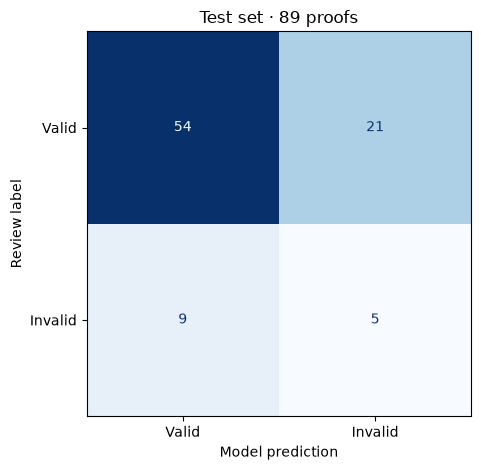

Of 14 Invalid proofs, the model caught 5 and missed 9.
Of 75 Valid proofs, it correctly accepted 54 and flagged 21 as Invalid.


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

predictions = {}
scores = []
for name in ("validation", "test"):
    data = datasets[name]
    actual = data["validity"]
    predictions[name] = baseline.predict(model_input(data))
    report = classification_report(actual, predictions[name], output_dict=True, zero_division=0)
    scores.append({
        "Split": name,
        "Proofs": len(data),
        "Actual Invalid": int(report["Invalid"]["support"]),
        "Invalid precision": report["Invalid"]["precision"],
        "Invalid recall": report["Invalid"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
    })

display(pd.DataFrame(scores).set_index("Split").round(3))

test_labels = datasets["test"]["validity"]
chart = ConfusionMatrixDisplay.from_predictions(
    test_labels, predictions["test"], labels=["Valid", "Invalid"],
    cmap="Blues", colorbar=False, values_format="d",
)
chart.ax_.set(title=f"Test set · {len(test_labels)} proofs",
              xlabel="Model prediction", ylabel="Review label")
plt.tight_layout()
plt.show()

correct_valid, false_alarm, missed, caught = chart.confusion_matrix.ravel()
print(f"Of {missed + caught} Invalid proofs, the model caught {caught} and missed {missed}.")
print(f"Of {correct_valid + false_alarm} Valid proofs, it correctly accepted {correct_valid} "
      f"and flagged {false_alarm} as Invalid.")

## 5. Train the baseline with the review reason

Add `review_reason` to the theorem and proof. Try the same six combinations and select the best validation Macro F1 for this input.

In [5]:
def input_with_reason(data):
    return model_input(data) + "\n" + data["review_reason"]


baseline_with_reason = train_baseline(input_with_reason(train), input_with_reason(validation))

ngram_range=(2, 4), C=1 | Validation Macro F1 = 0.4647
ngram_range=(2, 4), C=0.1 | Validation Macro F1 = 0.4702
ngram_range=(2, 4), C=10 | Validation Macro F1 = 0.4843
ngram_range=(3, 5), C=1 | Validation Macro F1 = 0.4647
ngram_range=(3, 5), C=0.1 | Validation Macro F1 = 0.4941
ngram_range=(3, 5), C=10 | Validation Macro F1 = 0.4777

Best: ngram_range=(3, 5), C=0.1 | Validation Macro F1 = 0.4941


## 6. Evaluate the baseline with the review reason

Use the same table and test confusion matrix as in section 4. Here the model also reads the review reason when predicting each label.

,Proofs,Actual Invalid,Invalid precision,Invalid recall,Macro F1
Split,,,,,
validation,89,15,0.179,0.333,0.494
test,89,14,0.240,0.429,0.557


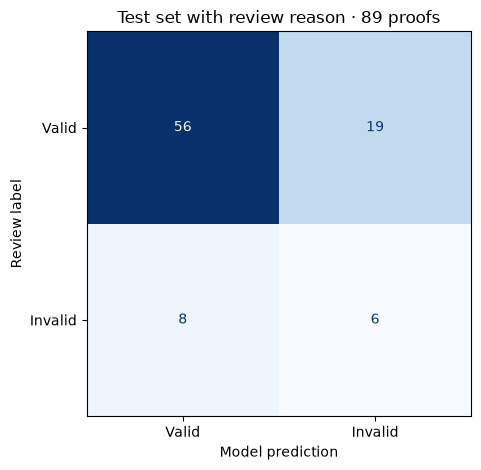

Of 14 Invalid proofs, the model caught 6 and missed 8.
Of 75 Valid proofs, it correctly accepted 56 and flagged 19 as Invalid.


In [6]:
predictions_with_reason = {}
scores_with_reason = []
for name in ("validation", "test"):
    data = datasets[name]
    actual = data["validity"]
    predictions_with_reason[name] = baseline_with_reason.predict(input_with_reason(data))
    report = classification_report(actual, predictions_with_reason[name], output_dict=True, zero_division=0)
    scores_with_reason.append({
        "Split": name,
        "Proofs": len(data),
        "Actual Invalid": int(report["Invalid"]["support"]),
        "Invalid precision": report["Invalid"]["precision"],
        "Invalid recall": report["Invalid"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
    })

display(pd.DataFrame(scores_with_reason).set_index("Split").round(3))

test_labels = datasets["test"]["validity"]
chart = ConfusionMatrixDisplay.from_predictions(
    test_labels, predictions_with_reason["test"], labels=["Valid", "Invalid"],
    cmap="Blues", colorbar=False, values_format="d",
)
chart.ax_.set(title=f"Test set with review reason · {len(test_labels)} proofs",
              xlabel="Model prediction", ylabel="Review label")
plt.tight_layout()
plt.show()

correct_valid, false_alarm, missed, caught = chart.confusion_matrix.ravel()
print(f"Of {missed + caught} Invalid proofs, the model caught {caught} and missed {missed}.")
print(f"Of {correct_valid + false_alarm} Valid proofs, it correctly accepted {correct_valid} "
      f"and flagged {false_alarm} as Invalid.")